In [1]:

from google.colab import files

uploaded = files.upload()


Saving online+retail.zip to online+retail.zip


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")



Libraries imported successfully!


In [3]:

df = pd.read_excel("Online Retail.xlsx")

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

df.head()


FileNotFoundError: [Errno 2] No such file or directory: 'Online Retail.xlsx'

In [4]:

from google.colab import files

uploaded = files.upload()


KeyboardInterrupt: 

In [5]:

import zipfile
import os

with zipfile.ZipFile('online+retail.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/retail_data')

print("ZIP File Extracted Successfully!")

print(os.listdir('/content/retail_data'))


ZIP File Extracted Successfully!
['Online Retail.xlsx']


In [6]:

import pandas as pd
import os

files_list = os.listdir('/content/retail_data')

print("Available Files:", files_list)


Available Files: ['Online Retail.xlsx']


In [7]:

df = pd.read_excel('/content/retail_data/Online Retail.xlsx')

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


Dataset Loaded Successfully!
Dataset Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [8]:

print("Dataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [9]:

display(df.head())


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [10]:

print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Rows:", df.duplicated().sum())

display(df.describe())


Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
Duplicate Rows: 5268


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [11]:

# Remove duplicate rows
df = df.drop_duplicates()

# Remove missing CustomerID
df = df.dropna(subset=['CustomerID'])

# Remove invalid quantity and price
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

# Convert CustomerID to integer
df['CustomerID'] = df['CustomerID'].astype(int)

print("Data Cleaning Completed!")
print("Cleaned Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())


Data Cleaning Completed!
Cleaned Dataset Shape: (392692, 8)

Missing Values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


In [12]:

# Convert InvoiceDate into datetime format
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Extract date features
df['Year'] = df['InvoiceDate'].dt.year
df['Month'] = df['InvoiceDate'].dt.month
df['MonthName'] = df['InvoiceDate'].dt.month_name()
df['Day'] = df['InvoiceDate'].dt.day
df['DayName'] = df['InvoiceDate'].dt.day_name()
df['Hour'] = df['InvoiceDate'].dt.hour

# Calculate Revenue
df['Revenue'] = df['Quantity'] * df['UnitPrice']

print("Feature Engineering Completed!")

display(df.head())


Feature Engineering Completed!


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Year,Month,MonthName,Day,DayName,Hour,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,2010,12,December,1,Wednesday,8,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,2010,12,December,1,Wednesday,8,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,2010,12,December,1,Wednesday,8,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,2010,12,December,1,Wednesday,8,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,2010,12,December,1,Wednesday,8,20.34


In [13]:

print("Updated Dataset Columns:")
print(df.columns.tolist())


Updated Dataset Columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Year', 'Month', 'MonthName', 'Day', 'DayName', 'Hour', 'Revenue']


In [14]:

# Calculate total revenue
total_revenue = df['Revenue'].sum()

# Calculate total orders
total_orders = df['InvoiceNo'].nunique()

# Calculate total customers
total_customers = df['CustomerID'].nunique()

# Calculate total products
total_products = df['StockCode'].nunique()

# Display results
print("===== E-COMMERCE SALES ANALYSIS =====")

print("Total Revenue:", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Products:", total_products)


average_order_value = total_revenue / total_orders

print("Average Order Value:", round(average_order_value, 2))


===== E-COMMERCE SALES ANALYSIS =====
Total Revenue: 8887208.89
Total Orders: 18532
Total Customers: 4338
Total Products: 3665
Average Order Value: 479.56


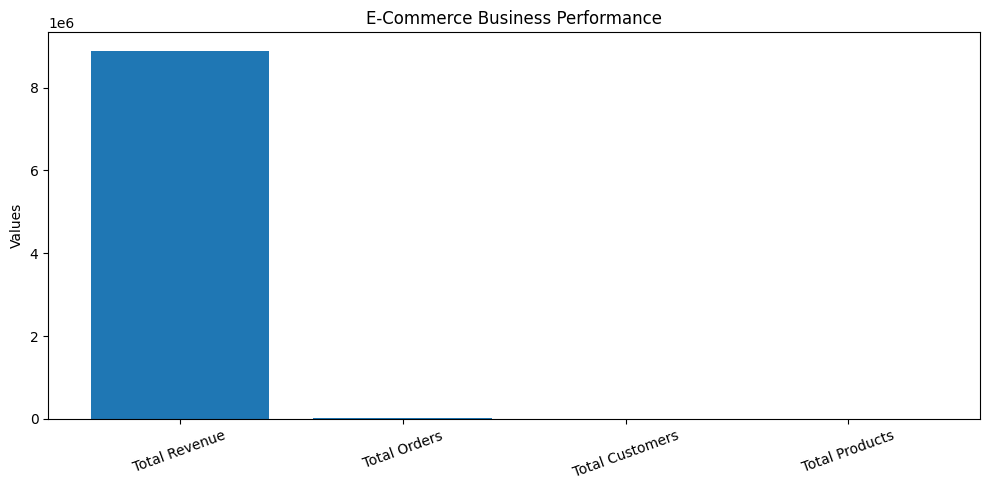

In [15]:

metrics = {
    'Total Revenue': total_revenue,
    'Total Orders': total_orders,
    'Total Customers': total_customers,
    'Total Products': total_products
}

plt.figure(figsize=(10,5))

plt.bar(metrics.keys(), metrics.values())

plt.title("E-Commerce Business Performance")
plt.ylabel("Values")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


========== TOP 10 CUSTOMERS ==========


,CustomerID,Total_Spending,Total_Orders,Total_Quantity,Average_Order_Value
1689,14646,280206.02,73,196915,134.97
4201,18102,259657.30,60,64124,602.45
3728,17450,194390.79,46,69973,578.54
3008,16446,168472.50,2,80997,56157.50
1879,14911,143711.17,201,80240,25.35
55,12415,124914.53,21,77374,174.95
1333,14156,117210.08,55,57768,84.02
3771,17511,91062.38,31,64549,94.56
2702,16029,80850.84,63,40108,335.48
0,12346,77183.60,1,74215,77183.60



========== CUSTOMER SEGMENT DISTRIBUTION ==========
Customer_Segment
Low Value       1446
Medium Value    1446
High Value      1446
Name: count, dtype: int64

========== SEGMENT ANALYSIS ==========


,Customer_Segment,Total_Customers,Total_Revenue,Average_Spending
0,Low Value,1446,317006.67,219.23
1,Medium Value,1446,1024481.29,708.49
2,High Value,1446,7545720.93,5218.34


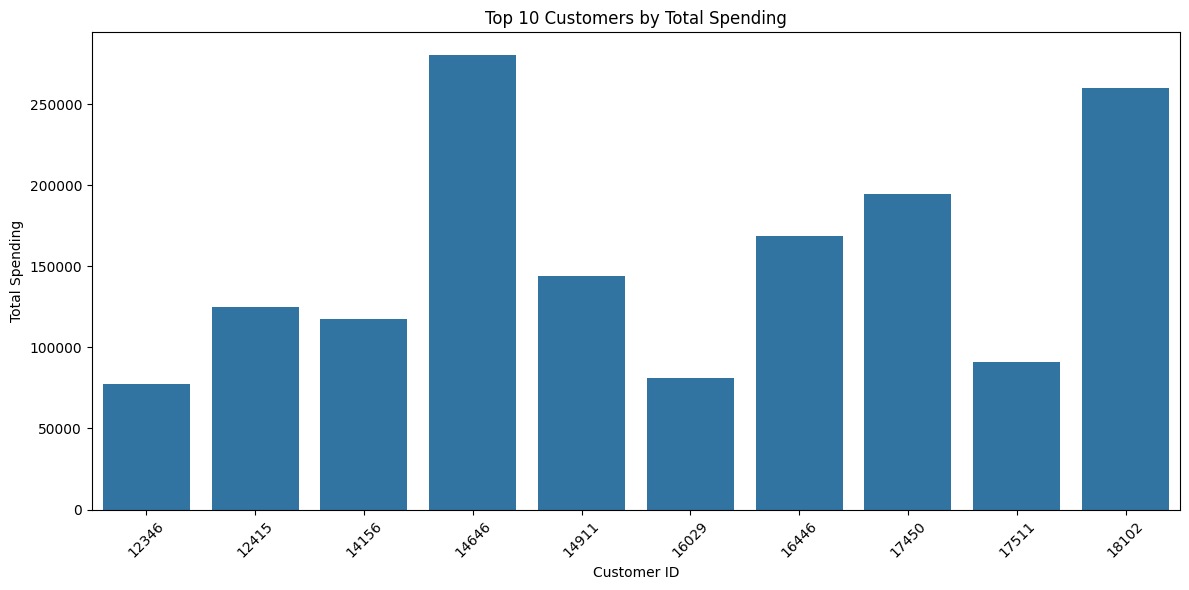

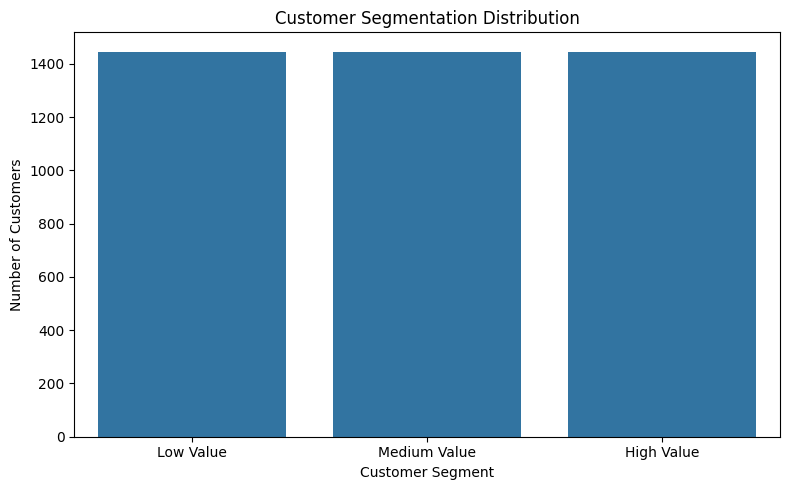

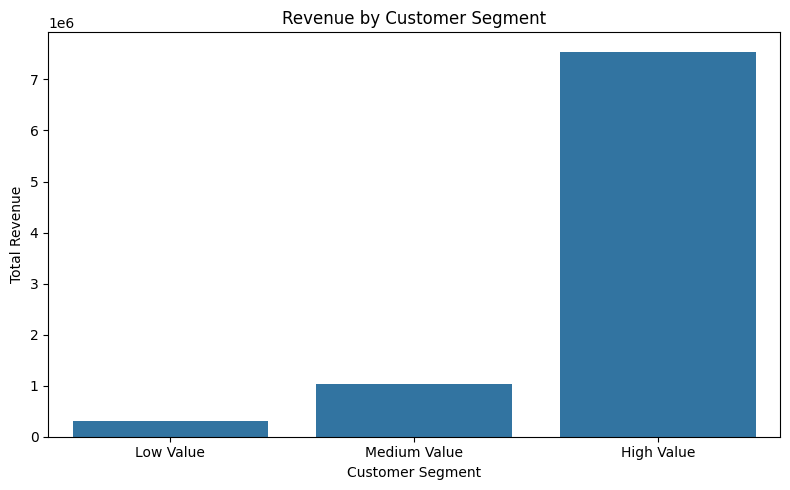


========== CUSTOMER INSIGHTS ==========
Total Customers: 4338
Highest Spending Customer ID: 14646
Highest Customer Spending: 280206.02

Customer Segmentation Completed Successfully!


In [16]:

# ==========================================
# STEP 8: CUSTOMER SEGMENTATION ANALYSIS
# ==========================================

# 1. Group customers and calculate metrics

customer_sales = df.groupby('CustomerID').agg(
    Total_Spending=('Revenue', 'sum'),
    Total_Orders=('InvoiceNo', 'nunique'),
    Total_Quantity=('Quantity', 'sum'),
    Average_Order_Value=('Revenue', 'mean')
).reset_index()


# 2. Sort customers by total spending

customer_sales = customer_sales.sort_values(
    by='Total_Spending',
    ascending=False
)


# 3. Display Top 10 Customers

print("========== TOP 10 CUSTOMERS ==========")

display(customer_sales.head(10).round(2))


# 4. Customer Segmentation based on spending

customer_sales['Customer_Segment'] = pd.qcut(
    customer_sales['Total_Spending'].rank(method='first'),
    q=3,
    labels=['Low Value', 'Medium Value', 'High Value']
)


# 5. Display customer segment counts

print("\n========== CUSTOMER SEGMENT DISTRIBUTION ==========")

print(customer_sales['Customer_Segment'].value_counts())


# 6. Segment-wise revenue analysis

segment_analysis = customer_sales.groupby(
    'Customer_Segment',
    observed=False
).agg(
    Total_Customers=('CustomerID', 'count'),
    Total_Revenue=('Total_Spending', 'sum'),
    Average_Spending=('Total_Spending', 'mean')
).reset_index()

print("\n========== SEGMENT ANALYSIS ==========")

display(segment_analysis.round(2))


# 7. Top 10 customer spending visualization

top_10 = customer_sales.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10,
    x='CustomerID',
    y='Total_Spending'
)

plt.title("Top 10 Customers by Total Spending")
plt.xlabel("Customer ID")
plt.ylabel("Total Spending")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 8. Customer segment visualization

plt.figure(figsize=(8, 5))

sns.countplot(
    data=customer_sales,
    x='Customer_Segment'
)

plt.title("Customer Segmentation Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


# 9. Segment revenue visualization

plt.figure(figsize=(8, 5))

sns.barplot(
    data=segment_analysis,
    x='Customer_Segment',
    y='Total_Revenue'
)

plt.title("Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()


# 10. Final customer insights

print("\n========== CUSTOMER INSIGHTS ==========")

print("Total Customers:", len(customer_sales))

print("Highest Spending Customer ID:",
      customer_sales.iloc[0]['CustomerID'])

print("Highest Customer Spending:",
      round(customer_sales.iloc[0]['Total_Spending'], 2))

print("\nCustomer Segmentation Completed Successfully!")


========== MONTHLY SALES DATA ==========


,Year,Month,MonthName,Revenue
0,2010,12,December,570422.73
1,2011,1,January,568101.31
2,2011,2,February,446084.92
3,2011,3,March,594081.76
4,2011,4,April,468374.33
5,2011,5,May,677355.15
6,2011,6,June,660046.05
7,2011,7,July,598962.90
8,2011,8,August,644051.04
9,2011,9,September,950690.20



========== HIGHEST SALES MONTH ==========
Month: November
Year: 2011
Revenue: 1156205.61

========== LOWEST SALES MONTH ==========
Month: February
Year: 2011
Revenue: 446084.92


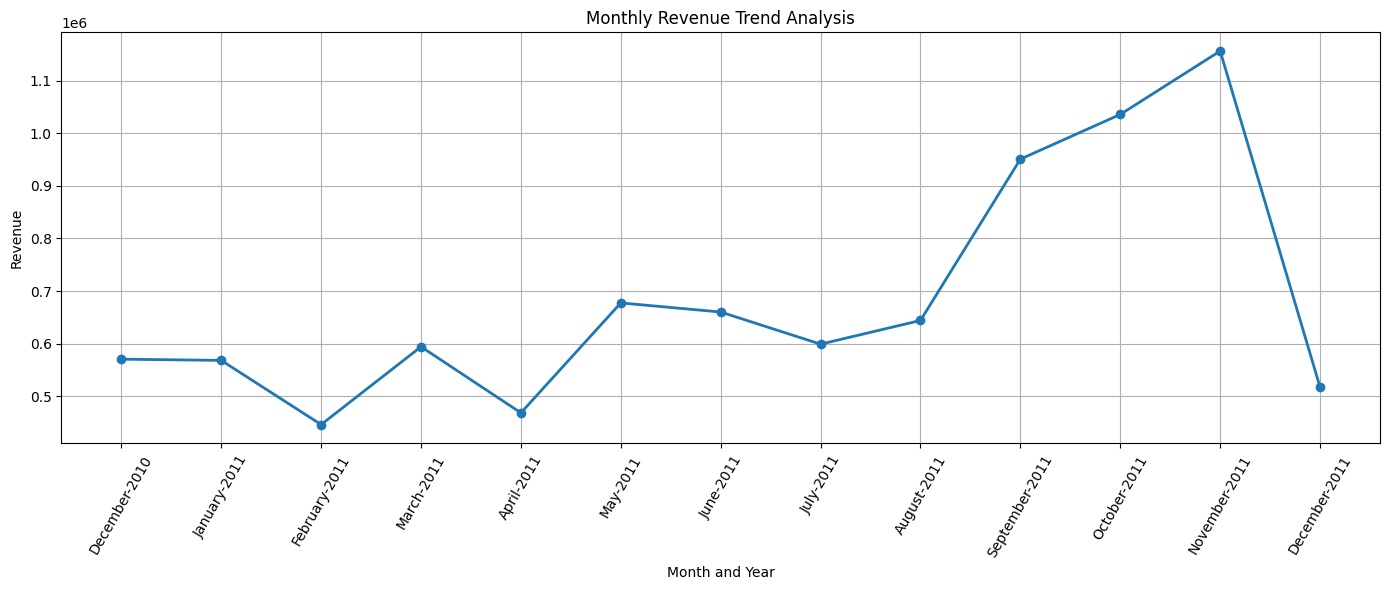

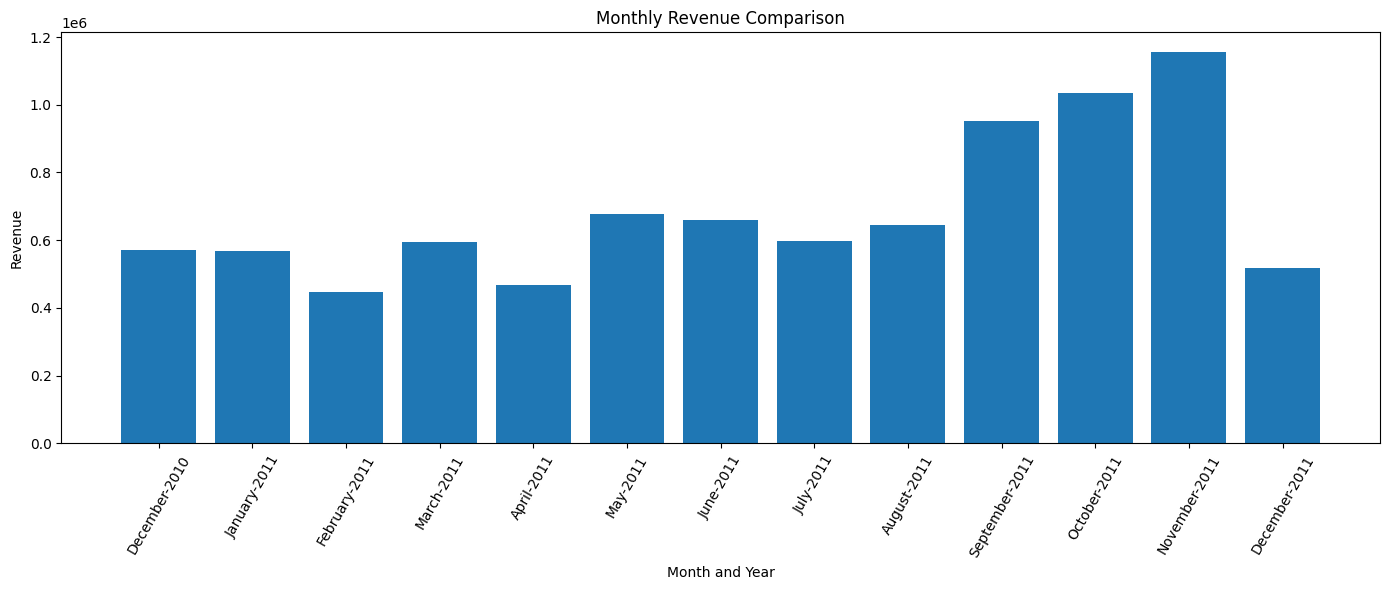


Average Monthly Revenue: 683631.45

========== SALES TREND INSIGHTS ==========
Highest Revenue: November 2011
Lowest Revenue: February 2011
Average Monthly Revenue: 683631.45

Monthly Sales Trend Analysis Completed!


In [17]:

# ==========================================
# STEP 9: MONTHLY SALES TREND ANALYSIS
# ==========================================

# 1. Group sales by year and month

monthly_sales = df.groupby(
    ['Year', 'Month', 'MonthName']
)['Revenue'].sum().reset_index()

# Sort by year and month
monthly_sales = monthly_sales.sort_values(
    ['Year', 'Month']
)

print("========== MONTHLY SALES DATA ==========")

display(monthly_sales.round(2))


# 2. Find highest revenue month

highest_month = monthly_sales.loc[
    monthly_sales['Revenue'].idxmax()
]

print("\n========== HIGHEST SALES MONTH ==========")

print("Month:", highest_month['MonthName'])
print("Year:", highest_month['Year'])
print("Revenue:", round(highest_month['Revenue'], 2))


# 3. Find lowest revenue month

lowest_month = monthly_sales.loc[
    monthly_sales['Revenue'].idxmin()
]

print("\n========== LOWEST SALES MONTH ==========")

print("Month:", lowest_month['MonthName'])
print("Year:", lowest_month['Year'])
print("Revenue:", round(lowest_month['Revenue'], 2))


# 4. Create month-year labels

monthly_sales['Month_Year'] = (
    monthly_sales['MonthName'] + "-" +
    monthly_sales['Year'].astype(str)
)


# 5. Monthly Revenue Trend Graph

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales['Month_Year'],
    monthly_sales['Revenue'],
    marker='o',
    linewidth=2
)

plt.title("Monthly Revenue Trend Analysis")
plt.xlabel("Month and Year")
plt.ylabel("Revenue")

plt.xticks(rotation=60)
plt.grid(True)
plt.tight_layout()
plt.show()


# 6. Monthly Revenue Bar Chart

plt.figure(figsize=(14, 6))

plt.bar(
    monthly_sales['Month_Year'],
    monthly_sales['Revenue']
)

plt.title("Monthly Revenue Comparison")
plt.xlabel("Month and Year")
plt.ylabel("Revenue")

plt.xticks(rotation=60)
plt.tight_layout()
plt.show()


# 7. Calculate Average Monthly Revenue

average_monthly_revenue = monthly_sales['Revenue'].mean()

print("\nAverage Monthly Revenue:",
      round(average_monthly_revenue, 2))


# 8. Final Insights

print("\n========== SALES TREND INSIGHTS ==========")

print("Highest Revenue:", highest_month['MonthName'],
      highest_month['Year'])

print("Lowest Revenue:", lowest_month['MonthName'],
      lowest_month['Year'])

print("Average Monthly Revenue:",
      round(average_monthly_revenue, 2))

print("\nMonthly Sales Trend Analysis Completed!")


========== YEAR-WISE REVENUE ==========


,Revenue
Year,
2010,570422.73
2011,8316786.16



========== MONTH-WISE REVENUE ==========


Year,2010,2011
Month,,
1,0.00,568101.31
2,0.00,446084.92
3,0.00,594081.76
4,0.00,468374.33
5,0.00,677355.15
6,0.00,660046.05
7,0.00,598962.90
8,0.00,644051.04
9,0.00,950690.20



========== COUNTRY-WISE REVENUE ==========


,Revenue
Country,
United Kingdom,7285024.64
Netherlands,285446.34
EIRE,265262.46
Germany,228678.40
France,208934.31
Australia,138453.81
Spain,61558.56
Switzerland,56443.95
Belgium,41196.34



========== TOP CUSTOMER REVENUE ==========


,Revenue
CustomerID,
14646,280206.02
18102,259657.30
17450,194390.79
16446,168472.50
14911,143711.17
12415,124914.53
14156,117210.08
17511,91062.38
16029,80850.84



========== MONTHLY SALES SUMMARY ==========


,Quantity,Revenue
MonthName,,
April,291366,468374.33
August,397373,644051.04
December,597825,1087613.17
February,265027,446084.92
January,348473,568101.31
July,367360,598962.90
June,363014,660046.05
March,347582,594081.76
May,372864,677355.15


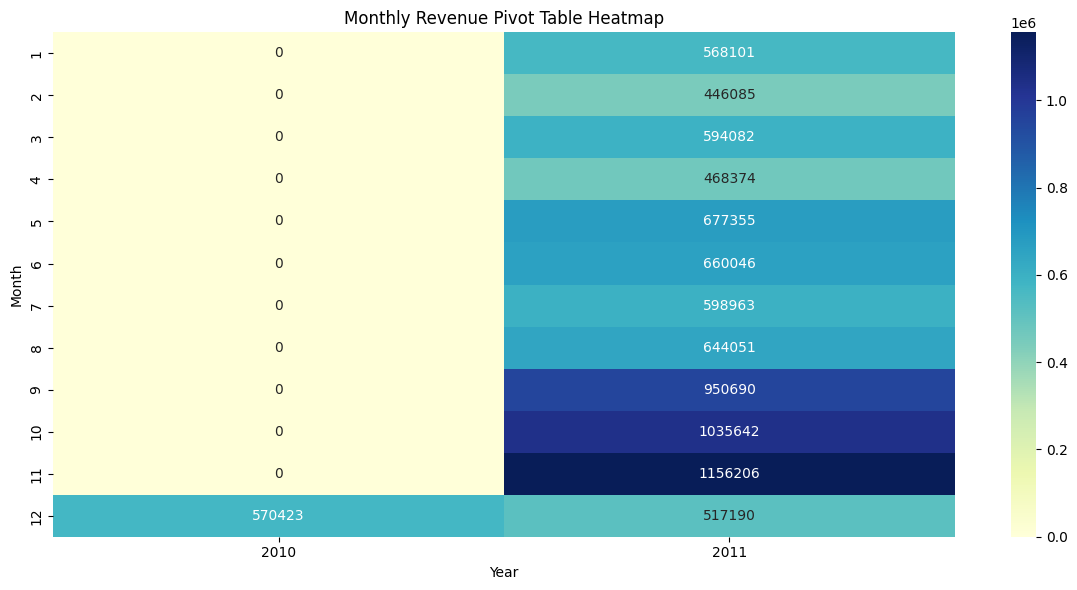

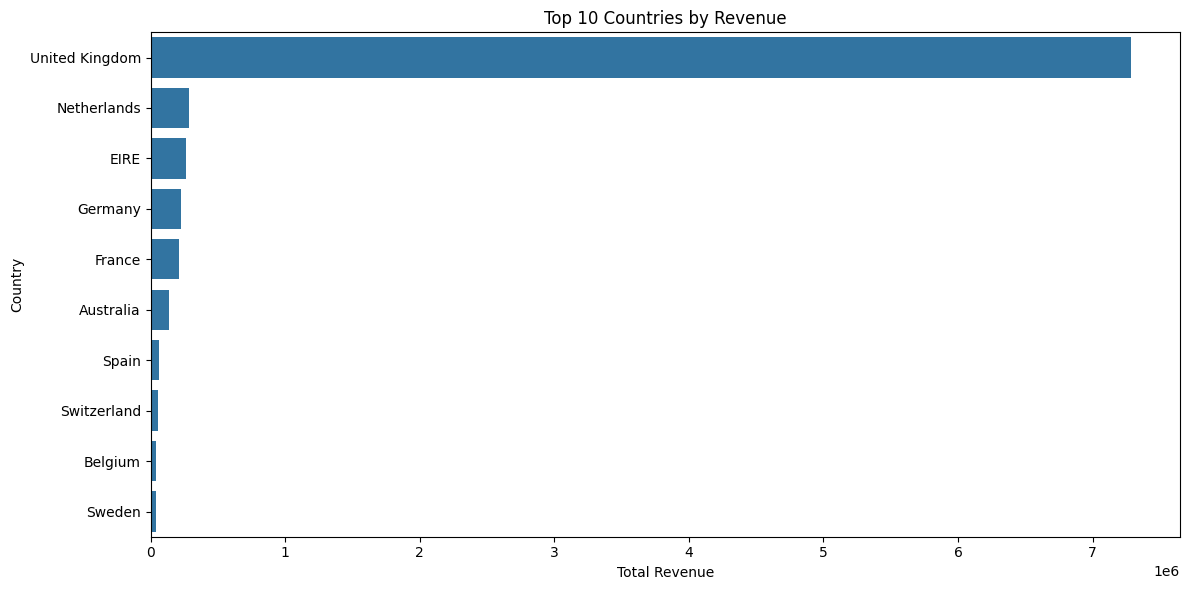


========== PIVOT TABLE SUMMARY ==========
Total Years: 2
Total Countries: 37
Highest Revenue Country: United Kingdom
Highest Revenue: 7285024.64

Pivot Table Analysis Completed Successfully!


In [18]:

# ==========================================
# STEP 10: PIVOT TABLE ANALYSIS
# ==========================================

# 1. Year-wise Revenue Pivot Table

year_pivot = pd.pivot_table(
    df,
    values='Revenue',
    index='Year',
    aggfunc='sum'
)

print("========== YEAR-WISE REVENUE ==========")
display(year_pivot.round(2))


# 2. Month-wise Revenue Pivot Table

month_pivot = pd.pivot_table(
    df,
    values='Revenue',
    index='Month',
    columns='Year',
    aggfunc='sum',
    fill_value=0
)

print("\n========== MONTH-WISE REVENUE ==========")
display(month_pivot.round(2))


# 3. Country-wise Revenue Pivot Table

country_pivot = pd.pivot_table(
    df,
    values='Revenue',
    index='Country',
    aggfunc='sum'
)

country_pivot = country_pivot.sort_values(
    by='Revenue',
    ascending=False
)

print("\n========== COUNTRY-WISE REVENUE ==========")
display(country_pivot.head(15).round(2))


# 4. Customer-wise Revenue Pivot Table

customer_pivot = pd.pivot_table(
    df,
    values='Revenue',
    index='CustomerID',
    aggfunc='sum'
)

customer_pivot = customer_pivot.sort_values(
    by='Revenue',
    ascending=False
)

print("\n========== TOP CUSTOMER REVENUE ==========")
display(customer_pivot.head(10).round(2))


# 5. Quantity and Revenue Pivot Table

sales_pivot = pd.pivot_table(
    df,
    values=['Revenue', 'Quantity'],
    index='MonthName',
    aggfunc={
        'Revenue': 'sum',
        'Quantity': 'sum'
    }
)

print("\n========== MONTHLY SALES SUMMARY ==========")
display(sales_pivot.round(2))


# 6. Heatmap Visualization

plt.figure(figsize=(12, 6))

sns.heatmap(
    month_pivot,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu'
)

plt.title("Monthly Revenue Pivot Table Heatmap")
plt.xlabel("Year")
plt.ylabel("Month")

plt.tight_layout()
plt.show()


# 7. Top 10 Countries Visualization

top_countries = country_pivot.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_countries['Revenue'].values,
    y=top_countries.index
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Country")

plt.tight_layout()
plt.show()


# 8. Final Summary

print("\n========== PIVOT TABLE SUMMARY ==========")

print("Total Years:", df['Year'].nunique())

print("Total Countries:", df['Country'].nunique())

print("Highest Revenue Country:",
      country_pivot.index[0])

print("Highest Revenue:",
      round(country_pivot.iloc[0]['Revenue'], 2))

print("\nPivot Table Analysis Completed Successfully!")


========== CUSTOMER CHURN DETAILS ==========


,CustomerID,Days_Inactive,Customer_Status
0,12346,326,Potential Churn
1,12347,2,Active
2,12348,75,Active
3,12349,19,Active
4,12350,310,Potential Churn
5,12352,36,Active
6,12353,204,Potential Churn
7,12354,232,Potential Churn
8,12355,214,Potential Churn
9,12356,23,Active



========== CUSTOMER STATUS SUMMARY ==========
Customer_Status
Active             2889
Potential Churn    1449
Name: count, dtype: int64

Total Customers: 4338
Active Customers: 2889
Potential Churn Customers: 1449
Potential Churn Percentage: 33.4 %
Active Customer Percentage: 66.6 %


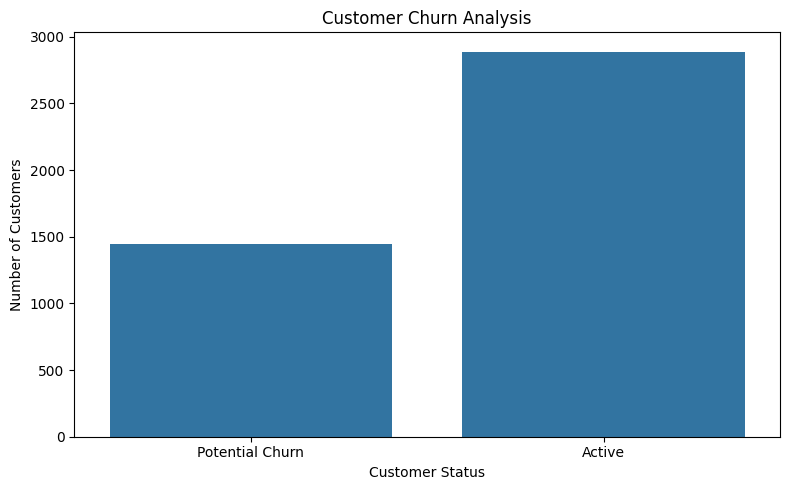

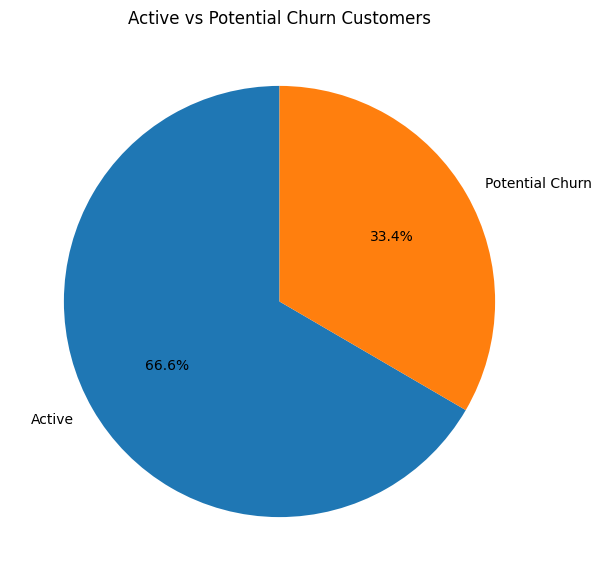

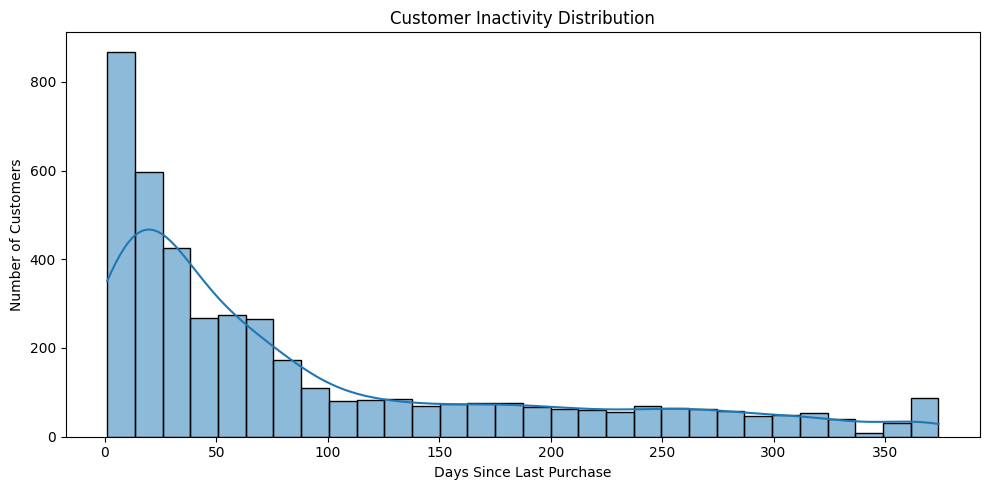


Customer Churn Analysis Completed Successfully!


In [19]:

# ==========================================
# STEP 11: CUSTOMER CHURN ANALYSIS
# ==========================================

# 1. Set reference date
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)


# 2. Find last purchase date of each customer
customer_last_purchase = df.groupby(
    'CustomerID'
)['InvoiceDate'].max()


# 3. Calculate inactive days
recency = (snapshot_date - customer_last_purchase).dt.days


# 4. Create churn analysis DataFrame
churn_analysis = recency.reset_index()

churn_analysis.columns = [
    'CustomerID',
    'Days_Inactive'
]


# 5. Classify customer status
churn_analysis['Customer_Status'] = np.where(
    churn_analysis['Days_Inactive'] > 90,
    'Potential Churn',
    'Active'
)


# 6. Display customer status
print("========== CUSTOMER CHURN DETAILS ==========")

display(churn_analysis.head(10))


# 7. Count customer status
status_counts = churn_analysis['Customer_Status'].value_counts()

print("\n========== CUSTOMER STATUS SUMMARY ==========")

print(status_counts)


# 8. Calculate churn percentage
total = len(churn_analysis)

potential_churn = status_counts.get('Potential Churn', 0)

active = status_counts.get('Active', 0)

churn_percentage = (potential_churn / total) * 100

retention_percentage = (active / total) * 100

print("\nTotal Customers:", total)

print("Active Customers:", active)

print("Potential Churn Customers:", potential_churn)

print("Potential Churn Percentage:",
      round(churn_percentage, 2), "%")

print("Active Customer Percentage:",
      round(retention_percentage, 2), "%")


# 9. Customer status bar chart
plt.figure(figsize=(8, 5))

sns.countplot(
    data=churn_analysis,
    x='Customer_Status'
)

plt.title("Customer Churn Analysis")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()


# 10. Customer status pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Active vs Potential Churn Customers")

plt.show()


# 11. Inactive days distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data=churn_analysis,
    x='Days_Inactive',
    bins=30,
    kde=True
)

plt.title("Customer Inactivity Distribution")
plt.xlabel("Days Since Last Purchase")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()


# 12. Export churn analysis
churn_analysis.to_csv(
    'customer_churn_analysis.csv',
    index=False
)

print("\nCustomer Churn Analysis Completed Successfully!")


========== TOP 10 SELLING PRODUCTS ==========


,Description,Total_Quantity,Total_Revenue,Total_Orders
2319,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
1992,MEDIUM CERAMIC TOP STORAGE JAR,77916,81416.73,195
3786,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54319,13558.41,472
1762,JUMBO BAG RED RETROSPOT,46078,85040.54,1600
3698,WHITE HANGING HEART T-LIGHT HOLDER,36706,100392.10,1971
216,ASSORTED COLOUR BIRD ORNAMENT,35263,56413.03,1375
2269,PACK OF 72 RETROSPOT CAKE CASES,33670,16381.88,1029
2600,POPCORN HOLDER,30919,23417.51,632
2656,RABBIT NIGHT LIGHT,27153,51251.24,801
2047,MINI PAINT SET VINTAGE,26076,16039.24,325



========== TOP 10 PRODUCTS BY REVENUE ==========


,Description,Total_Quantity,Total_Revenue,Total_Orders
2319,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
2767,REGENCY CAKESTAND 3 TIER,12374,142264.75,1703
3698,WHITE HANGING HEART T-LIGHT HOLDER,36706,100392.10,1971
1762,JUMBO BAG RED RETROSPOT,46078,85040.54,1600
1992,MEDIUM CERAMIC TOP STORAGE JAR,77916,81416.73,195
2611,POSTAGE,3120,77803.96,1099
2345,PARTY BUNTING,15279,68785.23,1379
216,ASSORTED COLOUR BIRD ORNAMENT,35263,56413.03,1375
2130,Manual,6933,53419.93,253
2656,RABBIT NIGHT LIGHT,27153,51251.24,801


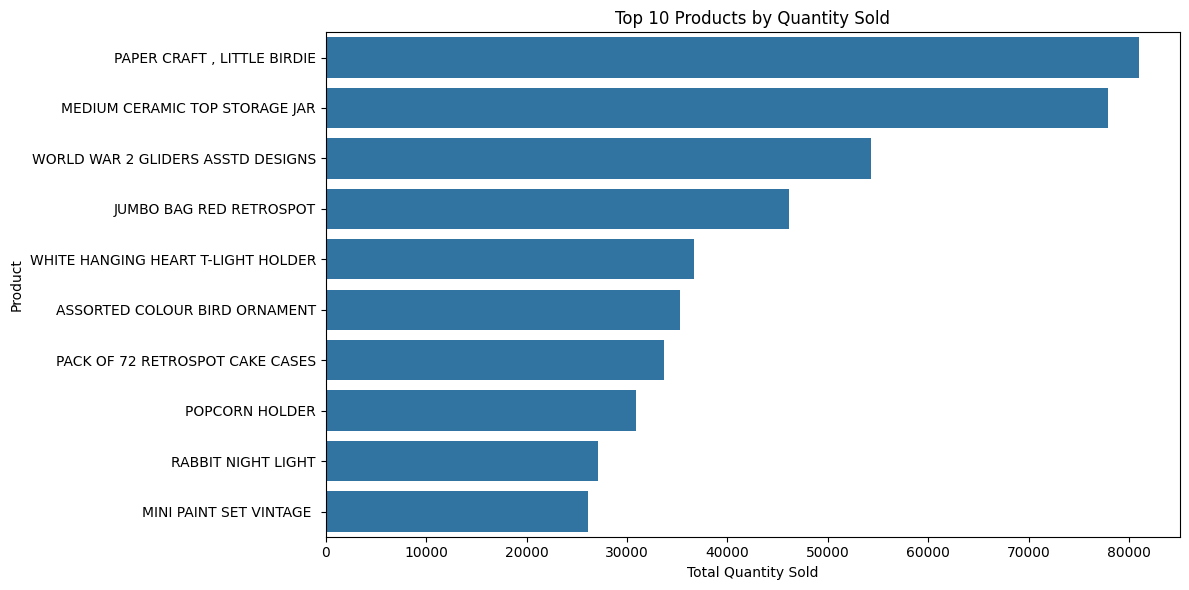

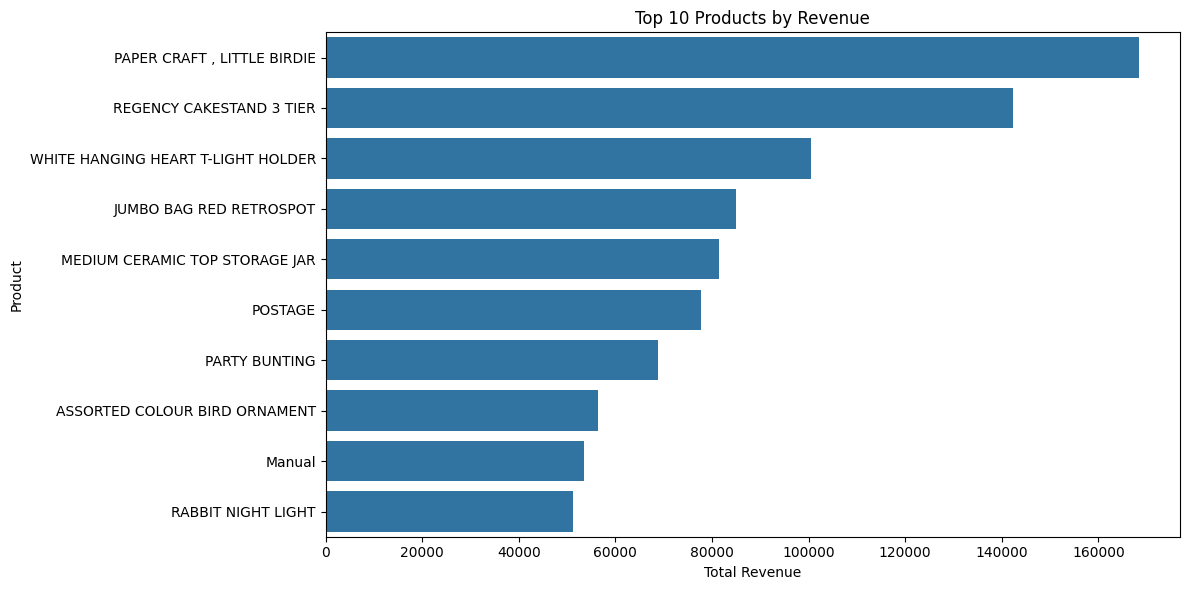


========== BEST PERFORMING PRODUCT ==========
Product: PAPER CRAFT , LITTLE BIRDIE
Total Revenue: 168469.6
Total Quantity: 80995

Total Products Analyzed: 3877

Product Sales Analysis Completed Successfully!


In [20]:

# ==========================================
# STEP 12: PRODUCT SALES ANALYSIS
# ==========================================

# 1. Product-wise sales analysis

product_sales = df.groupby('Description').agg(
    Total_Quantity=('Quantity', 'sum'),
    Total_Revenue=('Revenue', 'sum'),
    Total_Orders=('InvoiceNo', 'nunique')
).reset_index()


# 2. Remove empty product descriptions

product_sales = product_sales.dropna(
    subset=['Description']
)


# 3. Sort products by quantity sold

top_quantity_products = product_sales.sort_values(
    by='Total_Quantity',
    ascending=False
)

print("========== TOP 10 SELLING PRODUCTS ==========")

display(top_quantity_products.head(10).round(2))


# 4. Sort products by revenue

top_revenue_products = product_sales.sort_values(
    by='Total_Revenue',
    ascending=False
)

print("\n========== TOP 10 PRODUCTS BY REVENUE ==========")

display(top_revenue_products.head(10).round(2))


# 5. Top 10 quantity visualization

top_10_quantity = top_quantity_products.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_quantity,
    x='Total_Quantity',
    y='Description'
)

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")

plt.tight_layout()
plt.show()


# 6. Top 10 revenue visualization

top_10_revenue = top_revenue_products.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_revenue,
    x='Total_Revenue',
    y='Description'
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product")

plt.tight_layout()
plt.show()


# 7. Best performing product

best_product = top_revenue_products.iloc[0]

print("\n========== BEST PERFORMING PRODUCT ==========")

print("Product:", best_product['Description'])

print("Total Revenue:",
      round(best_product['Total_Revenue'], 2))

print("Total Quantity:",
      best_product['Total_Quantity'])


# 8. Total product count

print("\nTotal Products Analyzed:",
      len(product_sales))


# 9. Export product analysis

product_sales.to_csv(
    'product_sales_analysis.csv',
    index=False
)

print("\nProduct Sales Analysis Completed Successfully!")


========== COUNTRY-WISE SALES ANALYSIS ==========


,Country,Total_Revenue,Total_Orders,Total_Customers,Total_Quantity
35,United Kingdom,7285024.64,16646,3920,4241305
23,Netherlands,285446.34,94,9,200361
10,EIRE,265262.46,260,3,140133
14,Germany,228678.40,457,94,119154
13,France,208934.31,389,87,111428
0,Australia,138453.81,57,9,83891
30,Spain,61558.56,90,30,27933
32,Switzerland,56443.95,51,21,30082
3,Belgium,41196.34,98,25,23237
31,Sweden,38367.83,36,8,36078


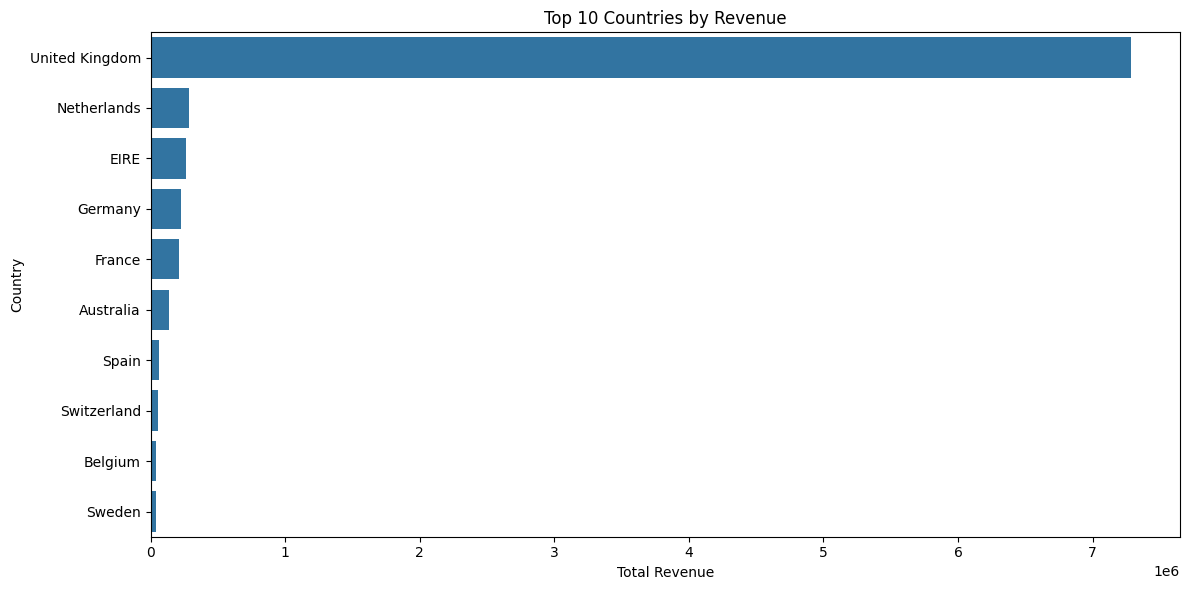

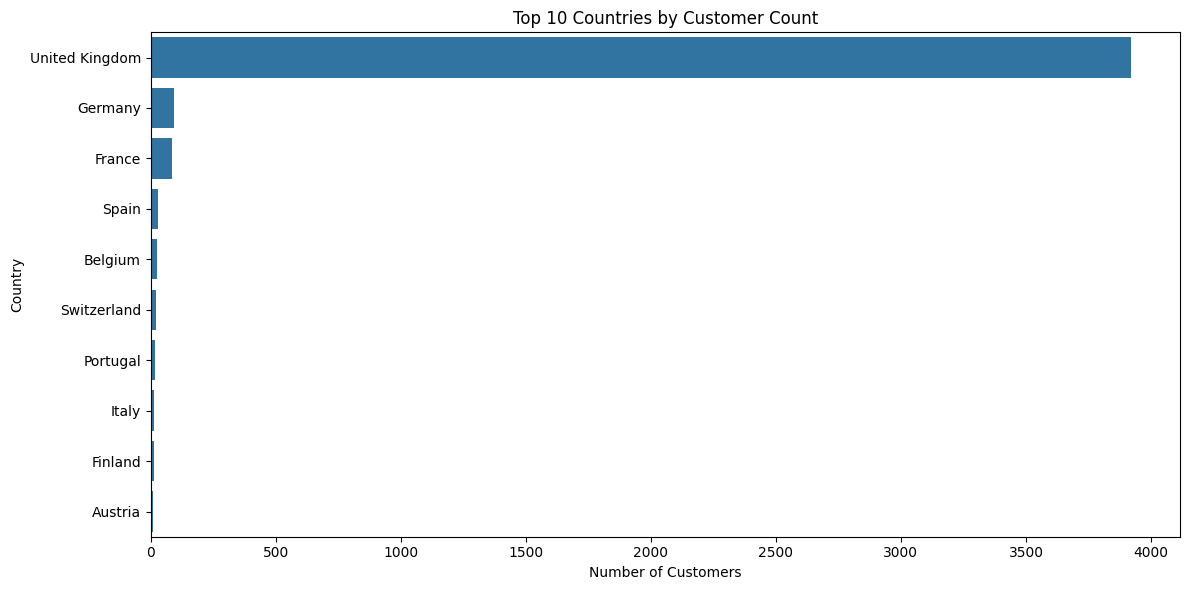

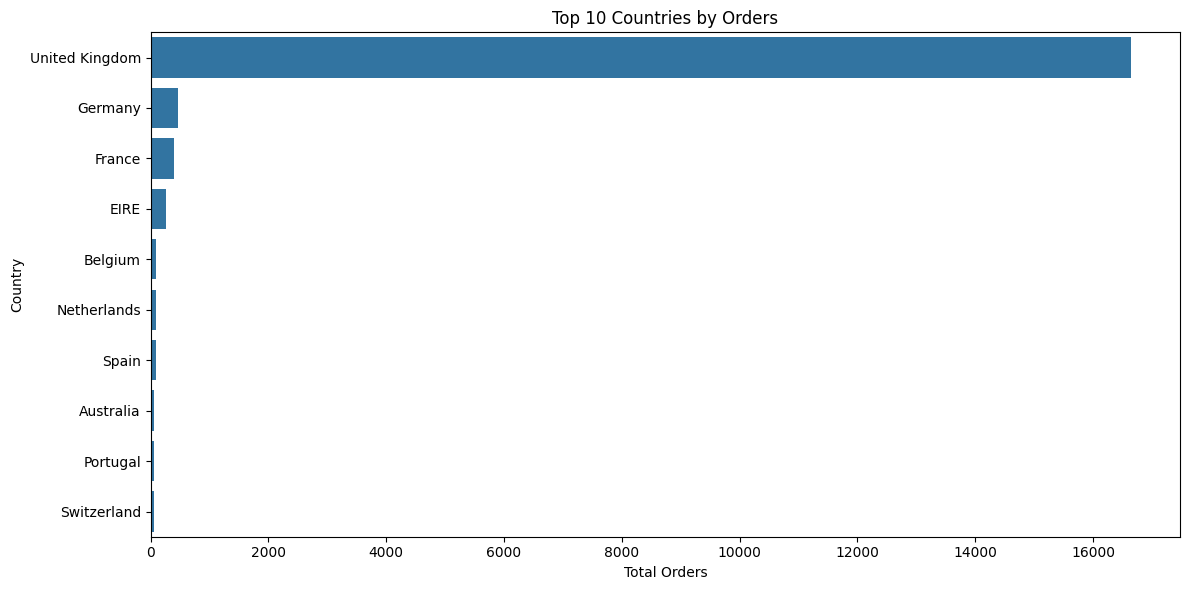


========== REVENUE CONTRIBUTION ==========


,Country,Total_Revenue,Revenue_Percentage
35,United Kingdom,7285024.64,81.97
23,Netherlands,285446.34,3.21
10,EIRE,265262.46,2.98
14,Germany,228678.40,2.57
13,France,208934.31,2.35
0,Australia,138453.81,1.56
30,Spain,61558.56,0.69
32,Switzerland,56443.95,0.64
3,Belgium,41196.34,0.46
31,Sweden,38367.83,0.43



========== BUSINESS INSIGHTS ==========
Highest Revenue Country: United Kingdom
Total Revenue: 7285024.64
Total Customers: 3920
Total Orders: 16646

Country-wise Sales Analysis Completed Successfully!


In [21]:

# ==========================================
# STEP 13: COUNTRY-WISE SALES ANALYSIS
# ==========================================

# 1. Group sales by country

country_analysis = df.groupby('Country').agg(
    Total_Revenue=('Revenue', 'sum'),
    Total_Orders=('InvoiceNo', 'nunique'),
    Total_Customers=('CustomerID', 'nunique'),
    Total_Quantity=('Quantity', 'sum')
).reset_index()


# 2. Sort countries by revenue

country_analysis = country_analysis.sort_values(
    by='Total_Revenue',
    ascending=False
)

print("========== COUNTRY-WISE SALES ANALYSIS ==========")

display(country_analysis.head(15).round(2))


# 3. Top 10 countries by revenue

top_countries = country_analysis.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_countries,
    x='Total_Revenue',
    y='Country'
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Country")

plt.tight_layout()
plt.show()


# 4. Top 10 countries by customers

top_customers_country = country_analysis.sort_values(
    by='Total_Customers',
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_customers_country,
    x='Total_Customers',
    y='Country'
)

plt.title("Top 10 Countries by Customer Count")
plt.xlabel("Number of Customers")
plt.ylabel("Country")

plt.tight_layout()
plt.show()


# 5. Country-wise order comparison

top_orders_country = country_analysis.sort_values(
    by='Total_Orders',
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_orders_country,
    x='Total_Orders',
    y='Country'
)

plt.title("Top 10 Countries by Orders")
plt.xlabel("Total Orders")
plt.ylabel("Country")

plt.tight_layout()
plt.show()


# 6. Calculate revenue contribution percentage

country_analysis['Revenue_Percentage'] = (
    country_analysis['Total_Revenue'] /
    country_analysis['Total_Revenue'].sum()
) * 100

print("\n========== REVENUE CONTRIBUTION ==========")

display(
    country_analysis[
        ['Country', 'Total_Revenue', 'Revenue_Percentage']
    ].head(10).round(2)
)


# 7. Identify highest revenue country

best_country = country_analysis.iloc[0]

print("\n========== BUSINESS INSIGHTS ==========")

print("Highest Revenue Country:",
      best_country['Country'])

print("Total Revenue:",
      round(best_country['Total_Revenue'], 2))

print("Total Customers:",
      best_country['Total_Customers'])

print("Total Orders:",
      best_country['Total_Orders'])


# 8. Export country analysis

country_analysis.to_csv(
    'country_sales_analysis.csv',
    index=False
)

print("\nCountry-wise Sales Analysis Completed Successfully!")


========== MONTHLY SALES GROWTH ==========


,Month,Revenue,Previous_Revenue,Revenue_Change,Growth_Percentage,Cumulative_Revenue
0,2010-12-31,570422.73,NaN,NaN,NaN,570422.73
1,2011-01-31,568101.31,570422.73,-2321.42,-0.41,1138524.04
2,2011-02-28,446084.92,568101.31,-122016.39,-21.48,1584608.96
3,2011-03-31,594081.76,446084.92,147996.84,33.18,2178690.72
4,2011-04-30,468374.33,594081.76,-125707.43,-21.16,2647065.05
5,2011-05-31,677355.15,468374.33,208980.82,44.62,3324420.20
6,2011-06-30,660046.05,677355.15,-17309.10,-2.56,3984466.25
7,2011-07-31,598962.90,660046.05,-61083.15,-9.25,4583429.15
8,2011-08-31,644051.04,598962.90,45088.14,7.53,5227480.19
9,2011-09-30,950690.20,644051.04,306639.16,47.61,6178170.39



Average Monthly Growth: 3.62 %

Highest Revenue Month: November 2011
Revenue: 1156205.61


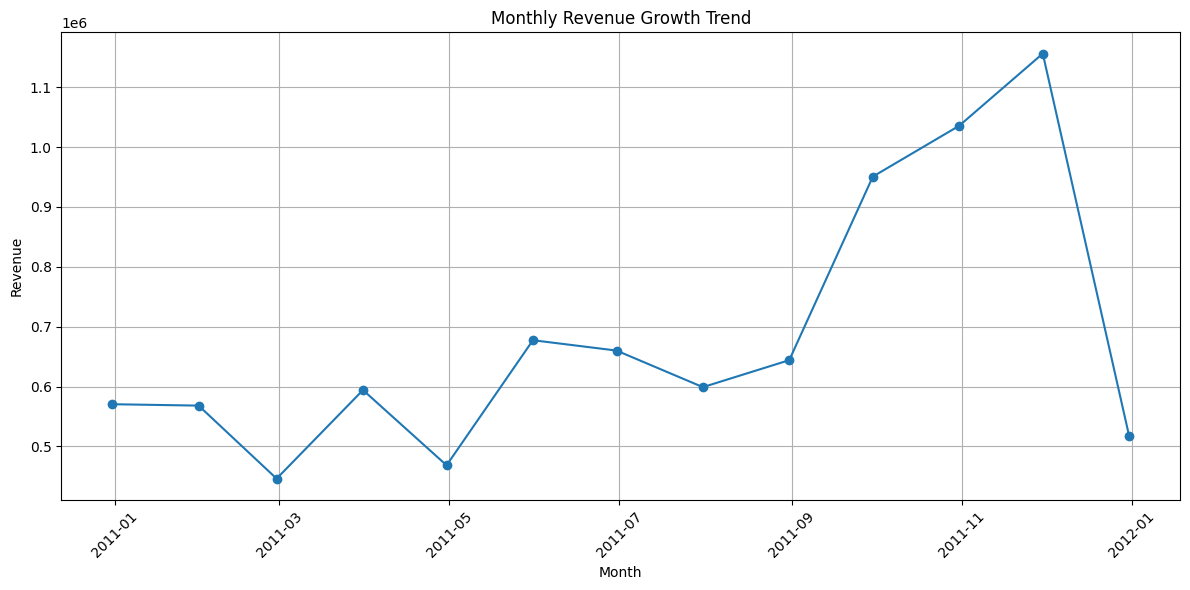

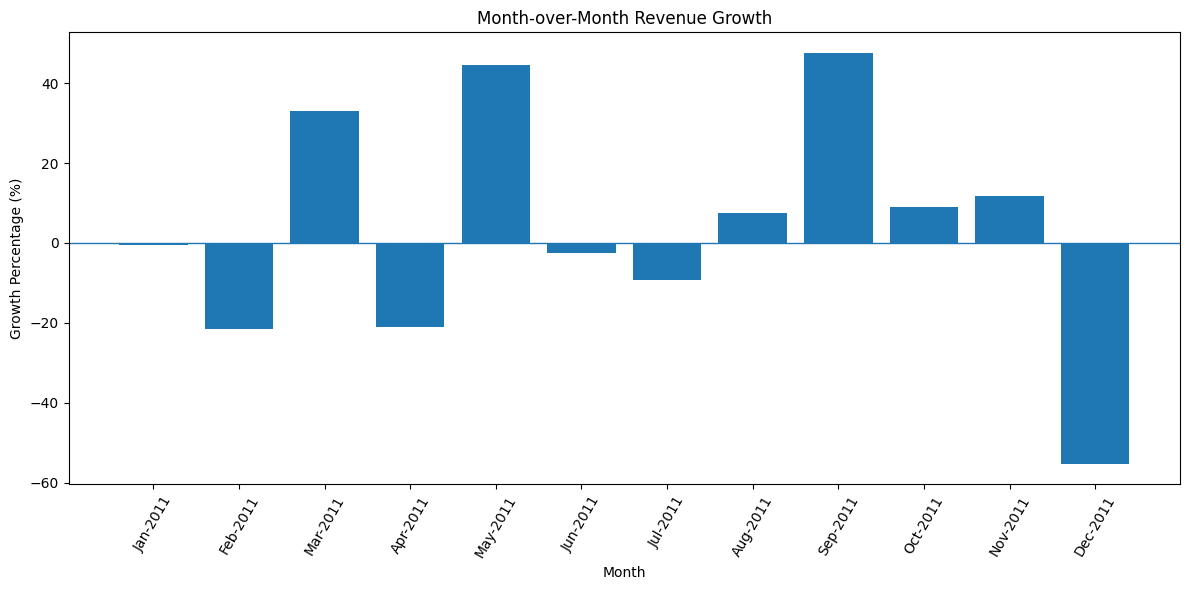

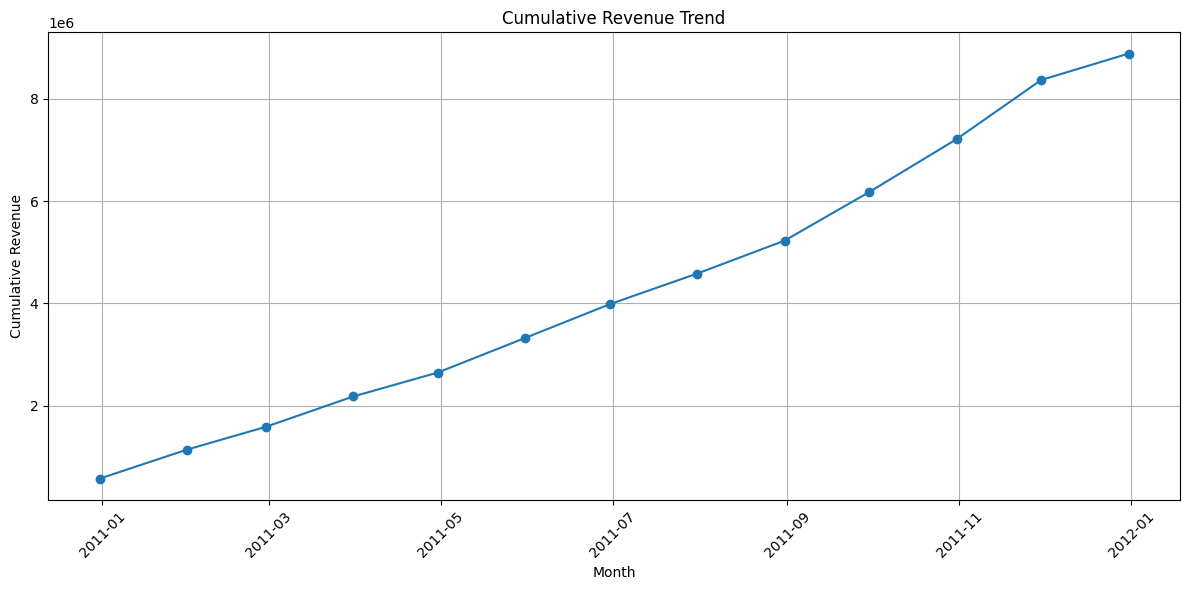


Sales Growth Analysis Completed Successfully!


In [22]:

# ==========================================
# STEP 14: SALES GROWTH & TREND ANALYSIS
# ==========================================

# 1. Calculate monthly revenue

monthly_trend = df.set_index(
    'InvoiceDate'
).resample('ME')['Revenue'].sum().reset_index()

monthly_trend.columns = ['Month', 'Revenue']


# 2. Calculate previous month's revenue

monthly_trend['Previous_Revenue'] = (
    monthly_trend['Revenue'].shift(1)
)


# 3. Calculate revenue difference

monthly_trend['Revenue_Change'] = (
    monthly_trend['Revenue'] -
    monthly_trend['Previous_Revenue']
)


# 4. Calculate growth percentage

monthly_trend['Growth_Percentage'] = (
    monthly_trend['Revenue'].pct_change() * 100
)


# 5. Calculate cumulative revenue

monthly_trend['Cumulative_Revenue'] = (
    monthly_trend['Revenue'].cumsum()
)


# 6. Display monthly growth table

print("========== MONTHLY SALES GROWTH ==========")

display(monthly_trend.round(2))


# 7. Calculate average monthly growth

average_growth = monthly_trend[
    'Growth_Percentage'
].mean()

print("\nAverage Monthly Growth:",
      round(average_growth, 2), "%")


# 8. Identify highest revenue month

highest = monthly_trend.loc[
    monthly_trend['Revenue'].idxmax()
]

print("\nHighest Revenue Month:",
      highest['Month'].strftime('%B %Y'))

print("Revenue:", round(highest['Revenue'], 2))


# 9. Revenue trend visualization

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_trend['Month'],
    monthly_trend['Revenue'],
    marker='o'
)

plt.title("Monthly Revenue Growth Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


# 10. Growth percentage visualization

growth_data = monthly_trend.dropna(
    subset=['Growth_Percentage']
)

plt.figure(figsize=(12, 6))

plt.bar(
    growth_data['Month'].dt.strftime('%b-%Y'),
    growth_data['Growth_Percentage']
)

plt.axhline(y=0, linewidth=1)

plt.title("Month-over-Month Revenue Growth")
plt.xlabel("Month")
plt.ylabel("Growth Percentage (%)")

plt.xticks(rotation=60)
plt.tight_layout()
plt.show()


# 11. Cumulative revenue visualization

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_trend['Month'],
    monthly_trend['Cumulative_Revenue'],
    marker='o'
)

plt.title("Cumulative Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Cumulative Revenue")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


# 12. Export results

monthly_trend.to_csv(
    'sales_growth_analysis.csv',
    index=False
)

print("\nSales Growth Analysis Completed Successfully!")


In [23]:

# ==========================================
# STEP 16: BUSINESS RECOMMENDATIONS
# ==========================================

print("=" * 55)
print("       E-COMMERCE BUSINESS ANALYSIS REPORT")
print("=" * 55)

# 1. Overall Business Performance

print("\n1. OVERALL BUSINESS PERFORMANCE")

print("Total Revenue:", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Products:", total_products)
print("Average Order Value:", round(average_order_value, 2))


# 2. Customer Analysis

print("\n2. CUSTOMER ANALYSIS")

print("High Value Customers:",
      (customer_sales['Customer_Segment'] == 'High Value').sum())

print("Medium Value Customers:",
      (customer_sales['Customer_Segment'] == 'Medium Value').sum())

print("Low Value Customers:",
      (customer_sales['Customer_Segment'] == 'Low Value').sum())


# 3. Churn Analysis

print("\n3. CUSTOMER CHURN ANALYSIS")

print("Potential Churn Customers:",
      (churn_analysis['Customer_Status'] == 'Potential Churn').sum())

print("Active Customers:",
      (churn_analysis['Customer_Status'] == 'Active').sum())


# 4. Product Analysis

print("\n4. PRODUCT PERFORMANCE")

best_product = top_revenue_products.iloc[0]

print("Best Revenue Product:", best_product['Description'])
print("Product Revenue:", round(best_product['Total_Revenue'], 2))


# 5. Country Analysis

print("\n5. COUNTRY PERFORMANCE")

best_country = country_analysis.iloc[0]

print("Top Revenue Country:", best_country['Country'])
print("Country Revenue:", round(best_country['Total_Revenue'], 2))


# 6. Business Recommendations

recommendations = [
    "Introduce loyalty rewards for high-value customers.",
    "Provide discounts to potential churn customers.",
    "Promote high-revenue generating products.",
    "Increase marketing in high-performing countries.",
    "Improve sales during low-revenue months.",
    "Maintain sufficient inventory for popular products.",
    "Use customer purchase history for personalized marketing."
]

print("\n6. BUSINESS RECOMMENDATIONS")

for i, recommendation in enumerate(recommendations, 1):
    print(f"{i}. {recommendation}")


# 7. Final Conclusion

print("\n7. PROJECT CONCLUSION")

print(
    "This analysis identifies customer purchasing patterns, "
    "revenue trends, product performance and potential churn risks."
)

print(
    "The findings help businesses improve customer retention, "
    "optimize sales strategies and make data-driven decisions."
)

print("\n" + "=" * 55)
print("       PROJECT ANALYSIS COMPLETED")
print("=" * 55)


       E-COMMERCE BUSINESS ANALYSIS REPORT

1. OVERALL BUSINESS PERFORMANCE
Total Revenue: 8887208.89
Total Orders: 18532
Total Customers: 4338
Total Products: 3665
Average Order Value: 479.56

2. CUSTOMER ANALYSIS
High Value Customers: 1446
Medium Value Customers: 1446
Low Value Customers: 1446

3. CUSTOMER CHURN ANALYSIS
Potential Churn Customers: 1449
Active Customers: 2889

4. PRODUCT PERFORMANCE
Best Revenue Product: PAPER CRAFT , LITTLE BIRDIE
Product Revenue: 168469.6

5. COUNTRY PERFORMANCE
Top Revenue Country: United Kingdom
Country Revenue: 7285024.64

6. BUSINESS RECOMMENDATIONS
1. Introduce loyalty rewards for high-value customers.
2. Provide discounts to potential churn customers.
3. Promote high-revenue generating products.
4. Increase marketing in high-performing countries.
5. Improve sales during low-revenue months.
6. Maintain sufficient inventory for popular products.
7. Use customer purchase history for personalized marketing.

7. PROJECT CONCLUSION
This analysis ide

In [24]:

import os
import shutil

# Create project folder
os.makedirs("Customer_Churn_Sales_Analysis", exist_ok=True)

folder = "Customer_Churn_Sales_Analysis"

# Export all analysis files
df.to_csv(f"{folder}/cleaned_sales_data.csv", index=False)

customer_sales.to_csv(
    f"{folder}/customer_segmentation.csv", index=False
)

churn_analysis.to_csv(
    f"{folder}/customer_churn_analysis.csv", index=False
)

monthly_sales.to_csv(
    f"{folder}/monthly_sales_trend.csv", index=False
)

country_analysis.to_csv(
    f"{folder}/country_sales_analysis.csv", index=False
)

product_sales.to_csv(
    f"{folder}/product_sales_analysis.csv", index=False
)

monthly_trend.to_csv(
    f"{folder}/sales_growth_analysis.csv", index=False
)

pivot_table.to_csv(
    f"{folder}/revenue_pivot_table.csv"
)

print("All Project Files Exported Successfully!")

print("\nExported Files:")
print(os.listdir(folder))


NameError: name 'pivot_table' is not defined

In [25]:

import os

folder = "Customer_Churn_Sales_Analysis"
os.makedirs(folder, exist_ok=True)

# Export analysis files
df.to_csv(f"{folder}/cleaned_sales_data.csv", index=False)
customer_sales.to_csv(f"{folder}/customer_segmentation.csv", index=False)
churn_analysis.to_csv(f"{folder}/customer_churn_analysis.csv", index=False)
monthly_sales.to_csv(f"{folder}/monthly_sales_trend.csv", index=False)
country_analysis.to_csv(f"{folder}/country_sales_analysis.csv", index=False)
product_sales.to_csv(f"{folder}/product_sales_analysis.csv", index=False)
monthly_trend.to_csv(f"{folder}/sales_growth_analysis.csv", index=False)

print("All Project Files Exported Successfully!")
print("\nExported Files:")
print(os.listdir(folder))


All Project Files Exported Successfully!

Exported Files:
['country_sales_analysis.csv', 'monthly_sales_trend.csv', 'customer_segmentation.csv', 'cleaned_sales_data.csv', 'customer_churn_analysis.csv', 'product_sales_analysis.csv', 'sales_growth_analysis.csv']


In [26]:

import shutil
from google.colab import files

# Create ZIP file
shutil.make_archive(
    "Customer_Churn_Sales_Analysis",
    "zip",
    "Customer_Churn_Sales_Analysis"
)

# Download ZIP file
files.download("Customer_Churn_Sales_Analysis.zip")

print("Project ZIP Download Started Successfully!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Project ZIP Download Started Successfully!
